In [ ]:
import torch

!nvidia-smi

print("PyTorch version:", torch.__version__)
print("PyTorch CUDA version:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("GPU is unavailable. Do not start training yet.")

Mon Nov 16 00:41:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%pip install -q ultralytics==8.4.213 openpyxl pandas pillow pillow-heif pyyaml scikit-learn matplotlib
from google.colab import drive, files
from pathlib import Path
from collections import defaultdict
from datetime import datetime
from PIL import Image
from pillow_heif import register_heif_opener
from ultralytics import YOLO
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import random, re, math, json, yaml, hashlib, shutil, tempfile, gc

register_heif_opener()
drive.mount('/content/drive')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
Device: 0


## Shared setup: paths and experiment settings

In [ ]:
BASE = Path('/content/drive/MyDrive/lecheros/Dataset')
PHOTOS = BASE / 'clean'
LABELS = BASE / 'recortes_v2/yolo_labels'
EXCEL = None
EXPERIMENT = 'YOLO_bcs'
ROOT = BASE / EXPERIMENT
ROOT.mkdir(parents=True, exist_ok=True)
REPORTS = ROOT / 'test_reports'
REPORTS.mkdir(exist_ok=True)
TEST_FRACTION = 0.20
VAL_WITHIN_DEVELOPMENT = 0.20
EPOCHS = 60
PATIENCE = 15
BATCH = 8
DET_SIZE = 640
CLS_SIZE = 224
CONFIDENCE = 0.25
DETECTOR_PRETRAINED = 'yolo26s.pt'
CLASSIFIER_PRETRAINED = 'yolo26s-cls.pt'
DROPOUT = 0.30

if EXCEL is None:
    uploaded = files.upload()
    names = [name for name in uploaded if name.lower().endswith('.xlsx')]
    if len(names) != 1:
        raise ValueError('Upload exactly one Excel file.')
    EXCEL = Path('/content') / names[0]
for path in [PHOTOS, LABELS, EXCEL]:
    if not path.exists():
        raise FileNotFoundError(path)
WORK = Path(tempfile.mkdtemp(prefix='bcs_holdout_'))
DET = WORK / 'detection'
CLS = WORK / 'classification'
print('Persistent experiment:', ROOT)
print('Local prepared data:', WORK)

Saving EntendiendoDatos_folds (1).xlsx to EntendiendoDatos_folds (1).xlsx
Persistent experiment: /content/drive/MyDrive/lecheros/Dataset/YOLO_bcs
Local prepared data: /tmp/bcs_holdout_ucrg3llz


In [ ]:
def canonical_id(value):
    value = str(value).strip().lower()
    return value[:-2] if value.endswith('.0') else value

def read_box(path):
    rows = [line.split() for line in Path(path).read_text().splitlines() if line.strip()]
    if len(rows) != 1 or len(rows[0]) != 5:
        raise ValueError(f'Expected one class/xc/yc/w/h box: {path}')
    values = np.asarray(rows[0], dtype=float)
    _, xc, yc, bw, bh = values
    if not np.isfinite(values).all() or not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
        raise ValueError(f'Invalid box: {path}')
    if xc-bw/2 < -1e-5 or yc-bh/2 < -1e-5 or xc+bw/2 > 1+1e-5 or yc+bh/2 > 1+1e-5:
        raise ValueError(f'Box outside image: {path}')
    return xc, yc, bw, bh

def pixel_box(box, size):
    xc, yc, bw, bh = box
    w, h = size
    return (max(0, math.floor((xc-bw/2)*w)), max(0, math.floor((yc-bh/2)*h)),
            min(w, math.ceil((xc+bw/2)*w)), min(h, math.ceil((yc+bh/2)*h)))

def square_pad(image):
    side = max(image.size)
    canvas = Image.new('RGB', (side, side), (114, 114, 114))
    canvas.paste(image, ((side-image.width)//2, (side-image.height)//2))
    return canvas

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        for block in iter(lambda: file.read(1024*1024), b''):
            digest.update(block)
    return digest.hexdigest()

table = pd.read_excel(EXCEL, sheet_name='Hoja 1')
table.columns = table.columns.str.strip()
table['score'] = pd.to_numeric(table['BCS'], errors='coerce')
table = table.dropna(subset=['NO Vac', 'score']).copy()
source_flag = pd.to_numeric(table['Rancho'], errors='raise')
ranch = table.loc[source_flag.eq(1)].copy()
ranch['cow_id'] = ranch['NO Vac'].map(canonical_id)
if not ranch['cow_id'].is_unique:
    raise ValueError('Duplicate observation IDs in Excel.')
ranch_lookup = ranch.set_index('cow_id')['score'].to_dict()
external_lookup = {}
for _, row in table.loc[source_flag.eq(0)].iterrows():
    name = 'ext_' + str(row['Vacas']).strip().lower()
    if name in external_lookup:
        raise ValueError(f'Duplicate external group: {name}')
    external_lookup[name] = float(row['score'])
print('External BCS mapping:', external_lookup)

label_index = defaultdict(list)
for path in sorted(LABELS.rglob('*')):
    if path.is_file() and path.suffix.lower() == '.txt':
        label_index[path.stem.lower()].append(path)
records, skipped, errors = [], [], []
for source in ['rancho', 'externo']:
    root = PHOTOS / source
    if not root.is_dir():
        raise FileNotFoundError(root)
    for path in sorted(root.rglob('*')):
        if not path.is_file() or path.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.heic'}:
            continue
        try:
            cow_id = canonical_id(path.relative_to(root).parts[0])
            if source == 'rancho':
                match = re.match(r'^(\d+(?:_r\d+)?)(?=_|$)', path.stem, re.I)
                if match is None or canonical_id(match.group(1)) != cow_id:
                    raise ValueError('Folder ID and filename ID disagree.')
                if cow_id not in ranch_lookup:
                    raise ValueError(f'Cow absent from Excel: {cow_id}')
                score = float(ranch_lookup[cow_id])
                animal_id = re.sub(r'_r\d+$', '', cow_id)
            else:
                if cow_id not in external_lookup or not path.stem.lower().startswith(cow_id + '_'):
                    raise ValueError('External folder/filename/Excel mapping disagrees.')
                score = external_lookup[cow_id]
                animal_id = cow_id
            matches = label_index[path.stem.lower()]
            if not matches:
                skipped.append({'image': str(path), 'reason': 'Missing matching TXT annotation'})
                continue
            if len(matches) != 1:
                raise ValueError('Multiple matching TXT files.')
            read_box(matches[0])
            with Image.open(path) as im:
                rgb = im.convert('RGB')
                # Pixel hash detects exact duplicates even across different file encodings.
                pixel_hash = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
            records.append(dict(image=str(path), label=str(matches[0]), source=source,
                                cow_id=cow_id, animal_id=animal_id, bcs=score,
                                image_hash=sha256_file(path), pixel_hash=pixel_hash,
                                label_hash=sha256_file(matches[0])))
        except Exception as exc:
            errors.append({'image': str(path), 'problem': str(exc)})
pd.DataFrame(skipped, columns=['image', 'reason']).to_csv(ROOT / 'skipped_images.csv', index=False)
if errors:
    display(pd.DataFrame(errors))
    raise ValueError('Fix the listed data problems before training.')
manifest = pd.DataFrame(records).sort_values('image').reset_index(drop=True)
if manifest.empty:
    raise ValueError('No eligible labeled images.')
if manifest['image'].map(lambda p: Path(p).stem.lower()).duplicated().any():
    raise ValueError('Duplicate image stems: label associations are ambiguous.')
print('Eligible photos:', len(manifest), '| Missing-label photos excluded:', len(skipped))
missing_cows = sorted(set(ranch_lookup) - set(manifest.loc[manifest.source.eq('rancho'), 'cow_id']))
print('Excel observation IDs without eligible photos:', missing_cows)
if skipped:
    display(pd.DataFrame(skipped).head(10))

External BCS mapping: {'ext_niu': 3.25, 'ext_mao': 3.5}
Eligible photos: 704 | Missing-label photos excluded: 128
Excel observation IDs without eligible photos: []


,image,reason
0,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
1,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
2,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
3,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
4,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
5,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
6,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
7,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
8,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation
9,/content/drive/MyDrive/lecheros/Dataset/clean/...,Missing matching TXT annotation


## Grouped split and class coverage
Select a label-balanced grouped split from deterministic candidates. All classes must remain represented in fit training (including the training-only external images). Candidate selection uses class counts only. It cannot create missing animals in rare classes; unsupported test classes are reported as such. Do not change the seed after seeing model results.

In [ ]:
def grouped_holdout(frame, fraction, seed, extra_training_scores=()):
    frame = frame.reset_index(drop=True)
    classes = sorted(frame['bcs'].unique())
    overall = frame['bcs'].value_counts(normalize=True).reindex(classes, fill_value=0)
    best = None
    splitter = GroupShuffleSplit(n_splits=2000, test_size=fraction, random_state=seed)
    for fit_idx, held_idx in splitter.split(frame, groups=frame['animal_id']):
        fit, held = frame.iloc[fit_idx], frame.iloc[held_idx]
        if not set(classes).issubset(set(fit['bcs']) | set(extra_training_scores)):
            continue
        distribution = held['bcs'].value_counts(normalize=True).reindex(classes, fill_value=0)
        cost = float(np.abs(distribution-overall).sum() + abs(len(held)/len(frame)-fraction))
        if best is None or cost < best[0]:
            best = (cost, fit.copy(), held.copy())
    if best is None:
        raise ValueError('No feasible grouped split with training class coverage. Inspect animal counts; do not split photos of one cow.')
    return best[1], best[2]

ranch_data = manifest.loc[manifest.source.eq('rancho')].copy()
external_data = manifest.loc[manifest.source.eq('externo')].copy()
external_scores = set(external_data['bcs'])
development, test_data = grouped_holdout(ranch_data, TEST_FRACTION, SEED, external_scores)
fit_data, val_data = grouped_holdout(development, VAL_WITHIN_DEVELOPMENT, SEED, external_scores)
assignments = {}
for split, frame in [('train', fit_data), ('val', val_data), ('test', test_data)]:
    for animal in frame['animal_id'].unique():
        assignments[animal] = split
manifest['split'] = [assignments[row.animal_id] if row.source == 'rancho' else 'train'
                     for row in manifest.itertuples()]
assert manifest.loc[manifest.source.eq('rancho')].groupby('animal_id')['split'].nunique().max() == 1
assert set(manifest['split']) == {'train', 'val', 'test'}
assert set(manifest['bcs']).issubset(set(manifest.loc[manifest.split.eq('train'), 'bcs']))
# Stop if exactly identical pixels cross splits, including external versus ranch.
cross_duplicates = manifest.groupby('pixel_hash')['split'].nunique()
if cross_duplicates.gt(1).any():
    display(manifest.loc[manifest.pixel_hash.isin(cross_duplicates[cross_duplicates.gt(1)].index)])
    raise ValueError('Exact duplicate images cross splits. Resolve duplicate identities before training.')

config = dict(seed=SEED, test_fraction=TEST_FRACTION, validation_fraction=VAL_WITHIN_DEVELOPMENT,
              epochs=EPOCHS, patience=PATIENCE, batch=BATCH, detector=DETECTOR_PRETRAINED,
              classifier=CLASSIFIER_PRETRAINED, dropout=DROPOUT, detector_size=DET_SIZE,
              classifier_size=CLS_SIZE, confidence=CONFIDENCE, ultralytics='8.4.213',
              external_policy='train_only', split_candidates=2000, implementation='holdout_v1')
manifest_text = manifest.to_csv(index=False)
fingerprint = hashlib.sha256((json.dumps(config, sort_keys=True)+manifest_text).encode()).hexdigest()
config_path = ROOT / 'experiment.json'
if config_path.exists():
    if json.loads(config_path.read_text())['fingerprint'] != fingerprint:
        raise ValueError('Data/settings differ from this saved experiment. Use a new EXPERIMENT name.')
else:
    config_path.write_text(json.dumps(dict(config=config, fingerprint=fingerprint), indent=2))
manifest.to_csv(ROOT / 'manifest.csv', index=False)
shutil.copy2(EXCEL, ROOT / 'expert_scores.xlsx')
print('Photo counts:')
display(pd.crosstab([manifest.source, manifest.split], manifest.bcs))
group_counts = manifest.loc[manifest.source.eq('rancho')].groupby('split')['animal_id'].nunique()
print('Ranch physical cows by split:')
display(group_counts.to_frame('Cows').assign(Percent=100*group_counts/group_counts.sum()))
coverage = pd.crosstab(manifest.bcs, manifest.split).reindex(columns=['train','val','test'], fill_value=0)
coverage['test_status'] = np.where(coverage['test'].eq(0), 'NOT EVALUATED: no test photos', 'Evaluated')
display(coverage)
coverage.to_csv(ROOT / 'class_split_counts.csv')

Photo counts:


bcs            2.00  2.25  2.50  2.75  3.00  3.25  3.50  3.75
source  split                                                
externo train     0     0     0     0     0    50    50     0
rancho  test      0     0    13    28    20    17    11    11
        train     4     2    70    96    85    67    38    40
        val       0     4    14    18    24    16    16    10

Ranch physical cows by split:


,Cows,Percent
split,,
test,16,20.00
train,51,63.75
val,13,16.25


split,train,val,test,test_status
bcs,,,,
2.00,4,0,0,NOT EVALUATED: no test photos
2.25,2,4,0,NOT EVALUATED: no test photos
2.50,70,14,13,Evaluated
2.75,96,18,28,Evaluated
3.00,85,24,20,Evaluated
3.25,117,16,17,Evaluated
3.50,88,16,11,Evaluated
3.75,40,10,11,Evaluated


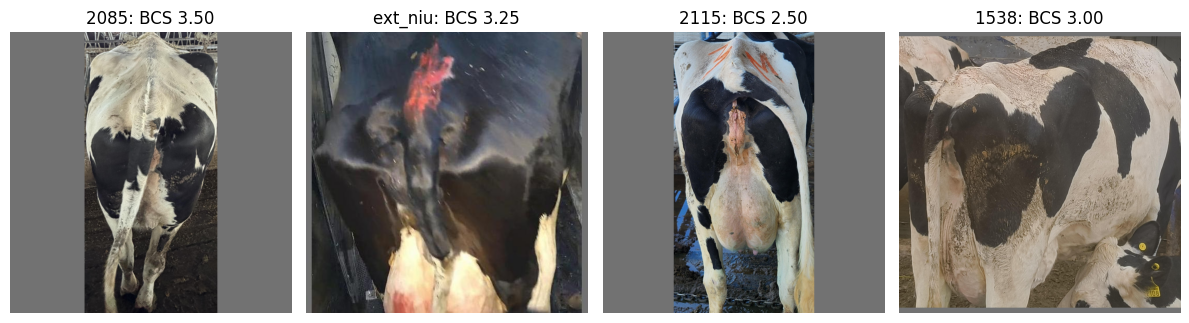

Prepared training, validation and test files.


In [ ]:
scores = sorted(manifest['bcs'].unique())
class_names = [f'{v:.2f}' for v in scores]
for split in ['train', 'val', 'test']:
    (DET / 'images' / split).mkdir(parents=True, exist_ok=True)
    (DET / 'labels' / split).mkdir(parents=True, exist_ok=True)
    for name in class_names:
        (CLS / split / name).mkdir(parents=True, exist_ok=True)
prepared = []
for i, row in manifest.iterrows():
    box = read_box(row.label)
    with Image.open(row.image) as original:
        image = original.convert('RGB')  # Match original annotation coordinates; no EXIF transpose.
    stem = f'image_{i:06d}'
    detection_image = DET / 'images' / row.split / f'{stem}.jpg'
    manual_crop = CLS / row.split / f'{row.bcs:.2f}' / f'{stem}.jpg'
    image.save(detection_image)
    (DET / 'labels' / row.split / f'{stem}.txt').write_text('0 ' + ' '.join(f'{x:.8f}' for x in box) + '\n')
    square_pad(image.crop(pixel_box(box, image.size))).save(manual_crop)
    prepared.append(dict(detection_image=str(detection_image), manual_crop=str(manual_crop)))
prepared = pd.concat([manifest.reset_index(drop=True), pd.DataFrame(prepared)], axis=1)
(DET / 'data.yaml').write_text(yaml.safe_dump(dict(path=str(DET), train='images/train',
                                                val='images/val', test='images/test', names={0:'cow'})))
# Preview only training crops before model fitting.
preview = prepared.loc[prepared.split.eq('train')].sample(min(4, (prepared.split=='train').sum()), random_state=SEED)
fig, axes = plt.subplots(1, len(preview), figsize=(12, 4), squeeze=False)
for ax, row in zip(axes[0], preview.itertuples()):
    with Image.open(row.manual_crop) as im:
        ax.imshow(im)
    ax.set_title(f'{row.cow_id}: BCS {row.bcs:.2f}')
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Prepared training, validation and test files.')

## Training helper
Only a completed checkpoint from this exact new experiment may be reused after reconnection. Old fold weights are never loaded. Partial runs are preserved in a backup folder and restarted from public pretrained weights. Training uses validation only; test evaluation is at the end.

In [ ]:
def train_model(name, pretrained, data, imgsz, dropout=None):
    run = ROOT / name
    marker = run / 'completed.json'
    best = run / 'weights/best.pt'
    settings = dict(name=name, pretrained=pretrained, imgsz=imgsz, dropout=dropout,
                    fingerprint=fingerprint)
    if marker.is_file() and best.is_file():
        if json.loads(marker.read_text()) != settings:
            raise ValueError(f'Checkpoint settings mismatch: {run}')
        print('Reusing completed model from this experiment:', best)
        return best
    if run.exists():
        backup = run.with_name(f'{name}_partial_{datetime.now():%Y%m%d_%H%M%S_%f}')
        run.rename(backup)
        print('Preserved incomplete run:', backup)
    model = YOLO(pretrained)
    kwargs = dict(data=str(data), epochs=EPOCHS, patience=PATIENCE, imgsz=imgsz,
                  batch=BATCH, device=DEVICE, workers=2, seed=SEED,
                  deterministic=True, project=str(ROOT), name=name, plots=True)
    if dropout is not None:
        kwargs['dropout'] = dropout
    model.train(**kwargs)
    actual_best = Path(model.trainer.best)
    if actual_best.resolve() != best.resolve() or not best.is_file():
        raise RuntimeError(f'Unexpected checkpoint path: {actual_best}')
    if dropout is not None:
        (run / 'bcs_class_mapping.json').write_text(json.dumps(model.names, indent=2))
    shutil.copy2(ROOT / 'manifest.csv', run / 'manifest.csv')
    marker.write_text(json.dumps(settings, indent=2))
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return best

# Part 1 — Bounding-box detector
Train one-class cow detection on original photos and their annotations. BCS is not predicted by this model. The saved training plots describe fit/validation, not test performance.

In [ ]:
detector_path = train_model('detector', DETECTOR_PRETRAINED, DET / 'data.yaml', DET_SIZE)
print(detector_path)

New https://pypi.org/project/ultralytics/8.4.214 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/bcs_holdout_ucrg3llz/detection/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yol